# Food Demand Analysis — Project Overview

This project examines weekly meal-delivery demand to describe demand patterns, fulfillment-center performance, and promotional activity. The workflow uses the original data as read-only inputs and distinguishes descriptive associations from causal conclusions.

# Imports and Data Loading

Import the Python libraries needed for tabular analysis, statistical comparisons, and plotting. Load the training, test, meal reference, and fulfillment-center reference CSV files from `data/raw` without changing the source files.

In [1]:
# Load the project datasets and verify the training data totals.
from pathlib import Path
from IPython.display import display

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats

project_root = next(
    (path.resolve() for path in (Path.cwd(), Path.cwd().parent) if (path / "data" / "raw").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project data/raw directory from the current folder.")

data_dir = project_root / "data" / "raw"
train_df = pd.read_csv(data_dir / "train.csv")
test_df = pd.read_csv(data_dir / "test.csv")
meal_df = pd.read_csv(data_dir / "meal_info.csv")
center_df = pd.read_csv(data_dir / "fulfilment_center_info.csv")

dataset_summary = pd.DataFrame(
    [
        {"File": name, "Rows": dataframe.shape[0], "Columns": dataframe.shape[1]}
        for name, dataframe in (
            ("train.csv", train_df),
            ("test.csv", test_df),
            ("meal_info.csv", meal_df),
            ("fulfilment_center_info.csv", center_df),
        )
    ]
)
print("Dataset Dimensions")
display(dataset_summary)

train_order_total = int(train_df["num_orders"].sum())
orders_summary = pd.DataFrame(
    [{"Metric": "Training Total Orders", "Value": f"{train_order_total:,}"}]
)
display(orders_summary)

assert len(train_df) == 456548, f"Unexpected training row count: {len(train_df)}"
assert train_order_total == 119557485, f"Unexpected training order total: {train_order_total}"

Dataset Dimensions


,File,Rows,Columns
0,train.csv,456548,9
1,test.csv,32573,8
2,meal_info.csv,51,3
3,fulfilment_center_info.csv,77,5


,Metric,Value
0,Training Total Orders,"119,557,485"


# Data Quality and Join Validation

Inspect schemas, missing values, key fields, and repeated observations. Validate reference-data joins as many-to-one, checking row counts, order totals where available, and unmatched keys before proceeding.

In [2]:
# Check source-data quality and validate reference joins without changing the inputs.
source_frames = {
    "train.csv": train_df,
    "test.csv": test_df,
    "meal_info.csv": meal_df,
    "fulfilment_center_info.csv": center_df,
}

missing_counts = {name: int(frame.isna().sum().sum()) for name, frame in source_frames.items()}
duplicate_row_counts = {name: int(frame.duplicated().sum()) for name, frame in source_frames.items()}
missing_duplicate_summary = pd.DataFrame(
    [
        {
            "File": name,
            "Missing Values": f"{missing_counts[name]:,}",
            "Fully Duplicated Rows": f"{duplicate_row_counts[name]:,}",
        }
        for name in source_frames
    ]
)
print("Missing Values and Duplicates")
display(missing_duplicate_summary)

assert all(count == 0 for count in missing_counts.values()), "Missing values found in source data."
assert all(count == 0 for count in duplicate_row_counts.values()), "Fully duplicated rows found in source data."

assert meal_df["meal_id"].is_unique, "meal_id is not unique in meal_df."
assert center_df["center_id"].is_unique, "center_id is not unique in center_df."
key_validation_rows = [
    {"Check": "meal_df meal_id uniqueness", "Result": "Passed" if meal_df["meal_id"].is_unique else "Failed"},
    {"Check": "center_df center_id uniqueness", "Result": "Passed" if center_df["center_id"].is_unique else "Failed"},
]
for name, frame in (("train_df", train_df), ("test_df", test_df)):
    duplicate_key_count = int(frame.duplicated(["week", "center_id", "meal_id"]).sum())
    key_validation_rows.append(
        {
            "Check": f"{name} duplicate (week, center_id, meal_id) rows",
            "Result": f"{duplicate_key_count:,}",
        }
    )
    assert duplicate_key_count == 0, f"Duplicate (week, center_id, meal_id) keys found in {name}."
key_validation_summary = pd.DataFrame(key_validation_rows)
print("Key Uniqueness and Duplicate Combinations")
display(key_validation_summary)

initial_rows = len(train_df)
initial_orders = int(train_df["num_orders"].sum())
meal_merge = train_df.merge(
    meal_df,
    on="meal_id",
    how="left",
    validate="many_to_one",
    indicator="_meal_match",
)
meal_unmatched = int(meal_merge["_meal_match"].ne("both").sum())
assert meal_unmatched == 0, f"Unmatched meal_id keys: {meal_unmatched}"
assert len(meal_merge) == initial_rows, f"Row count changed after meal join: {len(meal_merge)}"
assert int(meal_merge["num_orders"].sum()) == initial_orders, "Order total changed after meal join."
meal_merge = meal_merge.drop(columns="_meal_match")

merged_train_df = meal_merge.merge(
    center_df,
    on="center_id",
    how="left",
    validate="many_to_one",
    indicator="_center_match",
)
center_unmatched = int(merged_train_df["_center_match"].ne("both").sum())
assert center_unmatched == 0, f"Unmatched center_id keys: {center_unmatched}"
assert len(merged_train_df) == initial_rows, f"Row count changed after center join: {len(merged_train_df)}"
assert int(merged_train_df["num_orders"].sum()) == initial_orders, "Order total changed after center join."
merged_train_df = merged_train_df.drop(columns="_center_match")
assert len(merged_train_df) == 456548, f"Unexpected merged row count: {len(merged_train_df)}"
assert int(merged_train_df["num_orders"].sum()) == 119557485, "Unexpected merged order total."
join_validation_summary = pd.DataFrame(
    [
        {
            "Stage": "Before joins",
            "Rows": f"{initial_rows:,}",
            "Total Orders": f"{initial_orders:,}",
            "Unmatched Keys": "N/A",
        },
        {
            "Stage": "After meal_info join",
            "Rows": f"{len(meal_merge):,}",
            "Total Orders": f"{int(meal_merge['num_orders'].sum()):,}",
            "Unmatched Keys": f"{meal_unmatched:,}",
        },
        {
            "Stage": "After fulfillment center join",
            "Rows": f"{len(merged_train_df):,}",
            "Total Orders": f"{int(merged_train_df['num_orders'].sum()):,}",
            "Unmatched Keys": f"{center_unmatched:,}",
        },
    ]
)
print("Join Validation")
display(join_validation_summary)

higher_checkout_counts = {
    "train.csv": int(train_df["checkout_price"].gt(train_df["base_price"]).sum()),
    "test.csv": int(test_df["checkout_price"].gt(test_df["base_price"]).sum()),
}
nonpositive_price_counts = {
    "train.csv": int((train_df[["checkout_price", "base_price"]] <= 0).any(axis=1).sum()),
    "test.csv": int((test_df[["checkout_price", "base_price"]] <= 0).any(axis=1).sum()),
}
price_promotion_rows = [
    {
        "Check": "checkout_price > base_price",
        "Dataset": name,
        "Count": f"{higher_checkout_counts[name]:,}",
    }
    for name in source_frames
    if name in higher_checkout_counts
]
price_promotion_rows.extend(
    {
        "Check": "Rows with zero or negative prices",
        "Dataset": name,
        "Count": f"{nonpositive_price_counts[name]:,}",
    }
    for name in nonpositive_price_counts
)
assert all(count == 0 for count in nonpositive_price_counts.values()), "Zero or negative prices found."

promotion_columns = ["emailer_for_promotion", "homepage_featured"]
for name, frame in (("train_df", train_df), ("test_df", test_df)):
    invalid_promotion_values = {
        column: sorted(set(frame[column].dropna().unique()) - {0, 1})
        for column in promotion_columns
    }
    for column, invalid_values in invalid_promotion_values.items():
        price_promotion_rows.append(
            {
                "Check": f"{column} values outside {{0, 1}}",
                "Dataset": name,
                "Count": f"{len(invalid_values):,}",
            }
        )
    assert all(not values for values in invalid_promotion_values.values()), f"Invalid promotion values in {name}."
price_promotion_summary = pd.DataFrame(price_promotion_rows)
print("Price and Promotion Checks")
display(price_promotion_summary)

expected_weeks = set(range(1, 146))
train_weeks = set(train_df["week"].unique())
missing_weeks = sorted(expected_weeks - train_weeks)
extra_weeks = sorted(train_weeks - expected_weeks)
weekly_coverage_summary = pd.DataFrame(
    [
        {"Check": "Observed week range", "Result": f"{min(train_weeks):,}-{max(train_weeks):,}"},
        {"Check": "Missing weeks from 1 to 145", "Result": ", ".join(map(str, missing_weeks)) or "None"},
        {"Check": "Unexpected weeks outside 1 to 145", "Result": ", ".join(map(str, extra_weeks)) or "None"},
    ]
)
print("Weekly Coverage")
display(weekly_coverage_summary)
assert train_weeks == expected_weeks, "Training weeks do not cover 1 through 145 exactly."

print("All data-quality and join-validation checks passed.")

Missing Values and Duplicates


,File,Missing Values,Fully Duplicated Rows
0,train.csv,0,0
1,test.csv,0,0
2,meal_info.csv,0,0
3,fulfilment_center_info.csv,0,0


Key Uniqueness and Duplicate Combinations


,Check,Result
0,meal_df meal_id uniqueness,Passed
1,center_df center_id uniqueness,Passed
2,"train_df duplicate (week, center_id, meal_id) ...",0
3,"test_df duplicate (week, center_id, meal_id) rows",0


Join Validation


...

Price and Promotion Checks


,Check,Dataset,Count
0,checkout_price > base_price,train.csv,"116,101"
1,checkout_price > base_price,test.csv,"8,937"
2,Rows with zero or negative prices,train.csv,0
3,Rows with zero or negative prices,test.csv,0
4,"emailer_for_promotion values outside {0, 1}",train_df,0
5,"homepage_featured values outside {0, 1}",train_df,0
6,"emailer_for_promotion values outside {0, 1}",test_df,0
7,"homepage_featured values outside {0, 1}",test_df,0


Weekly Coverage


,Check,Result
0,Observed week range,1-145
1,Missing weeks from 1 to 145,None
2,Unexpected weeks outside 1 to 145,None


All data-quality and join-validation checks passed.


# Key Performance Indicators (KPIs)

Calculate demand, weekly averages, estimated revenue, record-level discount rates, and promotion coverage from the training data. Preserve negative discount rates and state metric definitions, units, and limitations.

In [3]:
# Calculate and validate core demand KPIs from the validated merged training data.
from IPython.display import display

if (merged_train_df["base_price"] <= 0).any():
    raise ValueError("base_price must be positive for discount percentage calculations.")

total_orders = int(merged_train_df["num_orders"].sum())
weekly_orders = merged_train_df.groupby("week")["num_orders"].sum()
average_weekly_orders = float(weekly_orders.mean())
estimated_revenue = float((merged_train_df["checkout_price"] * merged_train_df["num_orders"]).sum())
discount_pct = (merged_train_df["base_price"] - merged_train_df["checkout_price"]) / merged_train_df["base_price"] * 100
average_discount_pct = float(discount_pct.mean())
email_promotion_rate = float(merged_train_df["emailer_for_promotion"].mean() * 100)
homepage_promotion_rate = float(merged_train_df["homepage_featured"].mean() * 100)
any_promotion_rate = float(
    merged_train_df[["emailer_for_promotion", "homepage_featured"]].eq(1).any(axis=1).mean() * 100
)
weekly_demand_cv = float(weekly_orders.std(ddof=1) / weekly_orders.mean() * 100)

assert total_orders == 119557485, f"Unexpected total orders: {total_orders}"
assert len(weekly_orders) == 145, f"Expected 145 weekly totals, found {len(weekly_orders)}"
assert np.isfinite(
    [average_weekly_orders, estimated_revenue, average_discount_pct, email_promotion_rate,
     homepage_promotion_rate, any_promotion_rate, weekly_demand_cv]
).all(), "One or more KPI values are not finite."

kpi_rows = [
    {"KPI": "Total Orders", "Value": f"{total_orders:,}", "Unit": "orders"},
    {"KPI": "Average Weekly Orders", "Value": f"{average_weekly_orders:,.2f}", "Unit": "orders per week"},
    {"KPI": "Estimated Revenue", "Value": f"{estimated_revenue:,.2f}", "Unit": "price units (currency unspecified)"},
    {"KPI": "Average Discount Percentage", "Value": f"{average_discount_pct:.2f}%", "Unit": "% of base price per row"},
    {"KPI": "Email Promotion Rate", "Value": f"{email_promotion_rate:.2f}%", "Unit": "% of rows"},
    {"KPI": "Homepage Promotion Rate", "Value": f"{homepage_promotion_rate:.2f}%", "Unit": "% of rows"},
    {"KPI": "Any Promotion Rate", "Value": f"{any_promotion_rate:.2f}%", "Unit": "% of rows"},
    {"KPI": "Weekly Demand Coefficient of Variation (CV)", "Value": f"{weekly_demand_cv:.2f}%", "Unit": "% (sample SD, ddof=1)"},
]
kpi_summary = pd.DataFrame(kpi_rows, columns=["KPI", "Value", "Unit"])
display(kpi_summary)

,KPI,Value,Unit
0,Total Orders,"119,557,485",orders
1,Average Weekly Orders,"824,534.38",orders per week
2,Estimated Revenue,"31,922,771,040.11",price units (currency unspecified)
3,Average Discount Percentage,5.72%,% of base price per row
4,Email Promotion Rate,8.12%,% of rows
5,Homepage Promotion Rate,10.92%,% of rows
6,Any Promotion Rate,14.82%,% of rows
7,Weekly Demand Coefficient of Variation (CV),15.24%,"% (sample SD, ddof=1)"


# Weekly Demand Trends

Aggregate orders by the dataset's week index, examine changes across the observed sequence, and calculate a four-week moving average and descriptive trend statistics. Keep week numbers as supplied rather than converting them to calendar dates.

In [4]:
# Summarize weekly demand, moving averages, and its rank correlation with week number.
from IPython.display import display

expected_weeks = pd.Index(range(1, 146), name="week")
weekly_demand = merged_train_df.groupby("week")["num_orders"].sum().reindex(expected_weeks)
if weekly_demand.isna().any():
    missing_weeks = weekly_demand[weekly_demand.isna()].index.tolist()
    raise ValueError(f"Weekly demand is missing for weeks: {missing_weeks}")

average_weekly_orders = float(weekly_demand.mean())
peak_week = int(weekly_demand.idxmax())
peak_orders = int(weekly_demand.max())
lowest_week = int(weekly_demand.idxmin())
lowest_orders = int(weekly_demand.min())
first_20_average = float(weekly_demand.iloc[:20].mean())
last_20_average = float(weekly_demand.iloc[-20:].mean())
first_to_last_change_pct = (last_20_average - first_20_average) / first_20_average * 100
moving_average_4w = weekly_demand.rolling(window=4, min_periods=4).mean()
spearman_result = stats.spearmanr(weekly_demand.index, weekly_demand.to_numpy())
spearman_rho = float(spearman_result.statistic)
spearman_p_value = float(spearman_result.pvalue)

assert int(weekly_demand.sum()) == 119557485, "Weekly totals do not reconcile to the expected order total."
assert len(weekly_demand) == 145, f"Expected 145 weeks, found {len(weekly_demand)}"
assert peak_week == 48 and peak_orders == 1303457, "Unexpected peak week result."
assert lowest_week == 62 and lowest_orders == 380065, "Unexpected lowest week result."
assert np.isclose(average_weekly_orders, 824534.38, atol=0.01), "Average weekly orders differ from expected result."
assert np.isclose(first_20_average, 777058.20, atol=0.01), "First 20-week average differs from expected result."
assert np.isclose(last_20_average, 805151.00, atol=0.01), "Last 20-week average differs from expected result."
assert np.isclose(first_to_last_change_pct, 3.62, atol=0.01), "First-to-last period change differs from expected result."
assert np.isclose(spearman_rho, 0.1697, atol=0.0001), "Spearman correlation differs from expected result."

trend_summary = pd.DataFrame(
    [
        {"Metric": "Average Weekly Orders", "Value": f"{average_weekly_orders:,.2f}", "Unit": "orders per week"},
        {"Metric": "Peak Week", "Value": f"{peak_week:,}", "Unit": "week number"},
        {"Metric": "Peak Orders", "Value": f"{peak_orders:,}", "Unit": "orders"},
        {"Metric": "Lowest Week", "Value": f"{lowest_week:,}", "Unit": "week number"},
        {"Metric": "Lowest Orders", "Value": f"{lowest_orders:,}", "Unit": "orders"},
        {"Metric": "First 20 Weeks Average", "Value": f"{first_20_average:,.2f}", "Unit": "orders per week"},
        {"Metric": "Last 20 Weeks Average", "Value": f"{last_20_average:,.2f}", "Unit": "orders per week"},
        {"Metric": "Change: First 20 to Last 20 Weeks", "Value": f"{first_to_last_change_pct:+.2f}%", "Unit": "%"},
        {"Metric": "Spearman Correlation (rho)", "Value": f"{spearman_rho:.4f}", "Unit": "correlation coefficient"},
        {"Metric": "Spearman p-value", "Value": f"{spearman_p_value:.4g}", "Unit": "p-value"},
    ]
)
print("Weekly Demand Trend Summary")
display(trend_summary)

weekly_demand_table = pd.DataFrame(
    {
        "Week": weekly_demand.index,
        "Weekly Orders": weekly_demand.to_numpy(),
        "4-Week Moving Average": moving_average_4w.to_numpy(),
    }
)
weekly_demand_table["Weekly Orders"] = weekly_demand_table["Weekly Orders"].map(lambda value: f"{value:,.0f}")
weekly_demand_table["4-Week Moving Average"] = weekly_demand_table["4-Week Moving Average"].map(
    lambda value: "—" if pd.isna(value) else f"{value:,.2f}"
)
print("Weekly Orders and 4-Week Moving Average (First 10 Weeks)")
display(weekly_demand_table.head(10))

print("Note: Correlation does not establish causation, and weekly observations may exhibit temporal dependence.")

Weekly Demand Trend Summary


,Metric,Value,Unit
0,Average Weekly Orders,"824,534.38",orders per week
1,Peak Week,48,week number
2,Peak Orders,"1,303,457",orders
3,Lowest Week,62,week number
4,Lowest Orders,"380,065",orders
5,First 20 Weeks Average,"777,058.20",orders per week
6,Last 20 Weeks Average,"805,151.00",orders per week
7,Change: First 20 to Last 20 Weeks,+3.62%,%
8,Spearman Correlation (rho),0.1697,correlation coefficient
9,Spearman p-value,0.04123,p-value


Weekly Orders and 4-Week Moving Average (First 10 Weeks)


,Week,Weekly Orders,4-Week Moving Average
0,1,"792,261",—
1,2,"787,084",—
2,3,"695,262",—
3,4,"743,529","754,534.00"
4,5,"1,198,675","856,137.50"
5,6,"947,288","896,188.50"
6,7,"934,803","956,073.75"
7,8,"670,518","937,821.00"
8,9,"723,243","818,963.00"
9,10,"811,825","785,097.25"


Note: Correlation does not establish causation, and weekly observations may exhibit temporal dependence.


# Category and Meal Pareto Analysis

Join meal descriptions to training observations and summarize order volume and contribution by category and meal. Calculate cumulative shares to assess concentration without assuming a fixed Pareto relationship.

In [5]:
# Measure order concentration across meal categories and individual meals.
from IPython.display import display

total_orders = int(merged_train_df["num_orders"].sum())
if total_orders <= 0:
    raise ValueError("Total orders must be positive to calculate contribution shares.")

category_summary = (
    merged_train_df.groupby("category", as_index=False)
    .agg(Total_Orders=("num_orders", "sum"), Distinct_Meals=("meal_id", "nunique"))
    .sort_values("Total_Orders", ascending=False)
    .reset_index(drop=True)
)
category_summary["Share_Pct"] = category_summary["Total_Orders"] / total_orders * 100
category_summary["Cumulative_Pct"] = category_summary["Share_Pct"].cumsum()
category_count_80 = int((category_summary["Cumulative_Pct"] < 80).sum() + 1)
category_share_80 = float(category_summary.loc[category_count_80 - 1, "Cumulative_Pct"])

meal_summary = (
    merged_train_df.groupby(["meal_id", "category"], as_index=False)
    .agg(Total_Orders=("num_orders", "sum"))
    .sort_values("Total_Orders", ascending=False)
    .reset_index(drop=True)
)
meal_summary["Share_Pct"] = meal_summary["Total_Orders"] / total_orders * 100
meal_summary["Cumulative_Pct"] = meal_summary["Share_Pct"].cumsum()
meal_count_80 = int((meal_summary["Cumulative_Pct"] < 80).sum() + 1)
meal_share_80 = float(meal_summary.loc[meal_count_80 - 1, "Cumulative_Pct"])

assert int(category_summary["Total_Orders"].sum()) == total_orders, "Category order totals do not reconcile."
assert int(meal_summary["Total_Orders"].sum()) == total_orders, "Meal order totals do not reconcile."
assert category_summary["category"].nunique() == 14, "Unexpected category count."
assert meal_summary["meal_id"].nunique() == 51, "Unexpected meal count."
assert category_summary.iloc[0]["category"] == "Beverages", "Unexpected top category."
assert int(category_summary.iloc[0]["Total_Orders"]) == 40480525, "Unexpected top category order total."
assert category_count_80 == 5 and np.isclose(category_share_80, 81.3997, atol=0.01), "Unexpected category Pareto result."
assert meal_count_80 == 22 and np.isclose(meal_share_80, 81.1818, atol=0.01), "Unexpected meal Pareto result."

category_display = category_summary.rename(
    columns={
        "category": "Category",
        "Total_Orders": "Total Orders",
        "Distinct_Meals": "Distinct Meals",
        "Share_Pct": "Share %",
        "Cumulative_Pct": "Cumulative %",
    }
).copy()
category_display["Total Orders"] = category_display["Total Orders"].map(lambda value: f"{value:,}")
category_display["Distinct Meals"] = category_display["Distinct Meals"].map(lambda value: f"{value:,}")
for column in ["Share %", "Cumulative %"]:
    category_display[column] = category_display[column].map(lambda value: f"{value:.2f}%")
print("Orders by Category")
display(category_display[["Category", "Total Orders", "Distinct Meals", "Share %", "Cumulative %"]])

meal_display = meal_summary.head(10).rename(
    columns={
        "meal_id": "Meal ID",
        "category": "Category",
        "Total_Orders": "Total Orders",
        "Share_Pct": "Share %",
        "Cumulative_Pct": "Cumulative %",
    }
).copy()
meal_display["Meal ID"] = meal_display["Meal ID"].map(lambda value: f"{value:,}")
meal_display["Total Orders"] = meal_display["Total Orders"].map(lambda value: f"{value:,}")
for column in ["Share %", "Cumulative %"]:
    meal_display[column] = meal_display[column].map(lambda value: f"{value:.2f}%")
print("Top 10 Meals by Orders")
display(meal_display[["Meal ID", "Category", "Total Orders", "Share %", "Cumulative %"]])

pareto_summary = pd.DataFrame(
    [
        {"Metric": "Total Categories", "Value": f"{len(category_summary):,}"},
        {"Metric": "Categories Needed for 80%", "Value": f"{category_count_80:,}"},
        {"Metric": "Their Cumulative Share", "Value": f"{category_share_80:.2f}%"},
        {"Metric": "Total Meals", "Value": f"{len(meal_summary):,}"},
        {"Metric": "Meals Needed for 80%", "Value": f"{meal_count_80:,}"},
        {"Metric": "Their Cumulative Share", "Value": f"{meal_share_80:.2f}%"},
    ]
)
print("Pareto Summary")
display(pareto_summary)

Orders by Category


,Category,Total Orders,Distinct Meals,Share %,Cumulative %
0,Beverages,"40,480,525",12,33.86%,33.86%
1,Rice Bowl,"20,874,063",3,17.46%,51.32%
2,Sandwich,"17,636,782",3,14.75%,66.07%
3,Salad,"10,944,336",3,9.15%,75.22%
4,Pizza,"7,383,720",3,6.18%,81.40%
5,Other Snacks,"4,766,293",3,3.99%,85.39%
6,Starters,"4,649,122",3,3.89%,89.27%
7,Extras,"3,984,979",3,3.33%,92.61%
8,Seafood,"2,715,714",3,2.27%,94.88%
9,Desert,"1,940,754",3,1.62%,96.50%


Top 10 Meals by Orders


,Meal ID,Category,Total Orders,Share %,Cumulative %
0,"2,290",Rice Bowl,"9,770,303",8.17%,8.17%
1,"1,885",Beverages,"8,346,246",6.98%,15.15%
2,"1,754",Sandwich,"6,818,059",5.70%,20.86%
3,"1,993",Beverages,"6,656,856",5.57%,26.42%
4,"1,109",Rice Bowl,"6,367,773",5.33%,31.75%
5,"2,707",Beverages,"5,932,792",4.96%,36.71%
6,"1,971",Sandwich,"5,728,620",4.79%,41.50%
7,"2,826",Sandwich,"5,090,103",4.26%,45.76%
8,"1,727",Rice Bowl,"4,735,987",3.96%,49.72%
9,"1,062",Beverages,"4,712,795",3.94%,53.66%


Pareto Summary


,Metric,Value
0,Total Categories,14
1,Categories Needed for 80%,5
2,Their Cumulative Share,81.40%
3,Total Meals,51
4,Meals Needed for 80%,22
5,Their Cumulative Share,81.18%


# Fulfillment Center Performance

Combine training observations with fulfillment-center attributes to compare total demand and per-center demand by center type and region. Summarize center-level variation and describe associations without making causal claims.

In [6]:
# Compare center-type demand, individual center totals, and operating-area association.
from IPython.display import display

total_orders = int(merged_train_df["num_orders"].sum())
center_totals = (
    merged_train_df.groupby("center_id", as_index=False)
    .agg(
        Center_Type=("center_type", "first"),
        City_Code=("city_code", "first"),
        Region_Code=("region_code", "first"),
        Op_Area=("op_area", "first"),
        Total_Orders=("num_orders", "sum"),
    )
)

center_type_summary = (
    center_totals.groupby("Center_Type", as_index=False)
    .agg(
        Total_Orders=("Total_Orders", "sum"),
        Number_of_Centers=("center_id", "nunique"),
        Average_Total_Orders_per_Center=("Total_Orders", "mean"),
    )
)
center_type_summary["Share_of_Total_Orders_Pct"] = center_type_summary["Total_Orders"] / total_orders * 100
center_type_summary = center_type_summary.sort_values(
    "Average_Total_Orders_per_Center", ascending=False
).reset_index(drop=True)

top_10_centers = center_totals.nlargest(10, "Total_Orders").reset_index(drop=True)
top_10_share_pct = float(top_10_centers["Total_Orders"].sum() / total_orders * 100)
spearman_result = stats.spearmanr(center_totals["Op_Area"], center_totals["Total_Orders"])
spearman_rho = float(spearman_result.statistic)
spearman_p_value = float(spearman_result.pvalue)

assert int(center_totals["Total_Orders"].sum()) == total_orders == 119557485, "Center totals do not reconcile."
assert center_totals["center_id"].nunique() == 77, "Unexpected number of fulfillment centers."
expected_type_totals = {
    "TYPE_A": (68978517, 43),
    "TYPE_B": (29996073, 15),
    "TYPE_C": (20582895, 19),
}
for center_type, (expected_orders, expected_centers) in expected_type_totals.items():
    actual = center_type_summary.loc[center_type_summary["Center_Type"] == center_type].iloc[0]
    assert int(actual["Total_Orders"]) == expected_orders, f"Unexpected order total for {center_type}."
    assert int(actual["Number_of_Centers"]) == expected_centers, f"Unexpected center count for {center_type}."
assert center_type_summary.iloc[0]["Center_Type"] == "TYPE_B", "TYPE_B is not the highest by average center orders."
assert np.isclose(center_type_summary.iloc[0]["Average_Total_Orders_per_Center"], 1999738.20, atol=0.01)
assert np.isclose(top_10_share_pct, 25.93, atol=0.01), "Top 10 center share differs from expected result."
assert np.isclose(spearman_rho, 0.6884, atol=0.0001), "Spearman correlation differs from expected result."

center_type_display = center_type_summary.rename(
    columns={
        "Center_Type": "Center Type",
        "Total_Orders": "Total Orders",
        "Share_of_Total_Orders_Pct": "Share of Total Orders %",
        "Number_of_Centers": "Number of Centers",
        "Average_Total_Orders_per_Center": "Average Total Orders per Center",
    }
).copy()
center_type_display["Total Orders"] = center_type_display["Total Orders"].map(lambda value: f"{value:,}")
center_type_display["Share of Total Orders %"] = center_type_display["Share of Total Orders %"].map(lambda value: f"{value:.2f}%")
center_type_display["Number of Centers"] = center_type_display["Number of Centers"].map(lambda value: f"{value:,}")
center_type_display["Average Total Orders per Center"] = center_type_display["Average Total Orders per Center"].map(lambda value: f"{value:,.2f}")
print("Performance by Center Type")
display(center_type_display)

top_10_display = top_10_centers.rename(
    columns={
        "center_id": "Center ID",
        "Center_Type": "Center Type",
        "City_Code": "City Code",
        "Region_Code": "Region Code",
        "Op_Area": "Operating Area",
        "Total_Orders": "Total Orders",
    }
)[["Center ID", "Center Type", "City Code", "Region Code", "Operating Area", "Total Orders"]].copy()
for column in ["Center ID", "City Code", "Region Code", "Total Orders"]:
    top_10_display[column] = top_10_display[column].map(lambda value: f"{value:,}")
top_10_display["Operating Area"] = top_10_display["Operating Area"].map(lambda value: f"{value:.2f}")
print("Top 10 Centers by Total Orders")
display(top_10_display)

center_performance_summary = pd.DataFrame(
    [
        {"Metric": "Top 10 Centers' Share of Total Orders", "Value": f"{top_10_share_pct:.2f}%"},
        {"Metric": "Spearman Correlation: Operating Area vs. Center Orders", "Value": f"{spearman_rho:.4f}"},
        {"Metric": "Spearman p-value", "Value": f"{spearman_p_value:.4g}"},
        {"Metric": "Interpretation Note", "Value": "Association does not establish causation."},
    ]
)
print("Center Performance Summary")
display(center_performance_summary)

Performance by Center Type


,Center Type,Total Orders,Number of Centers,Average Total Orders per Center,Share of Total Orders %
0,TYPE_B,"29,996,073",15,"1,999,738.20",25.09%
1,TYPE_A,"68,978,517",43,"1,604,151.56",57.69%
2,TYPE_C,"20,582,895",19,"1,083,310.26",17.22%


Top 10 Centers by Total Orders


,Center ID,Center Type,City Code,Region Code,Operating Area,Total Orders
0,13,TYPE_B,590,56,6.70,"4,296,545"
1,43,TYPE_A,590,56,5.10,"3,920,294"
2,10,TYPE_B,590,56,6.30,"3,381,018"
3,52,TYPE_B,685,56,5.60,"3,125,835"
4,137,TYPE_A,590,56,4.40,"3,117,478"
5,67,TYPE_B,638,56,7.00,"2,839,493"
6,11,TYPE_A,679,56,3.70,"2,797,300"
7,174,TYPE_A,700,56,7.00,"2,792,587"
8,104,TYPE_A,647,56,4.50,"2,427,542"
9,27,TYPE_A,713,85,4.50,"2,297,698"


Center Performance Summary


,Metric,Value
0,Top 10 Centers' Share of Total Orders,25.93%
1,Spearman Correlation: Operating Area vs. Cente...,0.6884
2,Spearman p-value,4.555e-12
3,Interpretation Note,Association does not establish causation.


# Promotion and Demand Analysis

Compare email and homepage promotions separately, including within-meal-and-center comparisons across promoted and unpromoted weeks. Report descriptive differences and any exploratory tests with explicit caveats about repeated observations, overlap, confounding, and causal interpretation.

In [7]:
# Compare promotional and non-promotional demand overall and within meal-center pairs.
from IPython.display import display

expected_rows = 456548
expected_orders = 119557485
assert len(merged_train_df) == expected_rows, f"Unexpected training rows: {len(merged_train_df)}"
assert int(merged_train_df["num_orders"].sum()) == expected_orders, "Unexpected training order total."
promotion_columns = {
    "Email Promotion": "emailer_for_promotion",
    "Homepage Featured": "homepage_featured",
}
for column in promotion_columns.values():
    assert set(merged_train_df[column].dropna().unique()).issubset({0, 1}), f"Unexpected values in {column}."

overall_rows = []
matched_rows = []
test_rows = []
overlap_rows = int(merged_train_df["emailer_for_promotion"].eq(1).mul(merged_train_df["homepage_featured"].eq(1)).sum())

for promotion_name, promotion_column in promotion_columns.items():
    promoted_mask = merged_train_df[promotion_column].eq(1)
    non_promoted_mask = merged_train_df[promotion_column].eq(0)
    promoted_orders = merged_train_df.loc[promoted_mask, "num_orders"]
    non_promoted_orders = merged_train_df.loc[non_promoted_mask, "num_orders"]
    promoted_mean = float(promoted_orders.mean())
    non_promoted_mean = float(non_promoted_orders.mean())
    mean_difference_pct = (
        (promoted_mean - non_promoted_mean) / non_promoted_mean * 100
        if non_promoted_mean != 0
        else np.nan
    )
    overall_rows.extend(
        [
            {
                "Promotion": promotion_name,
                "Group": "Promoted",
                "Number of Rows": int(promoted_mask.sum()),
                "Mean Orders": promoted_mean,
                "Median Orders": float(promoted_orders.median()),
                "Percentage Difference in Mean Orders": mean_difference_pct,
            },
            {
                "Promotion": promotion_name,
                "Group": "Not Promoted",
                "Number of Rows": int(non_promoted_mask.sum()),
                "Mean Orders": non_promoted_mean,
                "Median Orders": float(non_promoted_orders.median()),
                "Percentage Difference in Mean Orders": np.nan,
            },
        ]
    )

    pair_flag_counts = merged_train_df.groupby(["meal_id", "center_id"])[promotion_column].agg(
        promoted_weeks=lambda values: values.eq(1).sum(),
        non_promoted_weeks=lambda values: values.eq(0).sum(),
    )
    eligible_pairs = pair_flag_counts.index[
        pair_flag_counts["promoted_weeks"].gt(0) & pair_flag_counts["non_promoted_weeks"].gt(0)
    ]
    matched_observations = merged_train_df.loc[
        merged_train_df.set_index(["meal_id", "center_id"]).index.isin(eligible_pairs),
        ["meal_id", "center_id", promotion_column, "num_orders"],
    ]
    pair_means = matched_observations.groupby(["meal_id", "center_id", promotion_column])["num_orders"].mean().unstack(promotion_column)
    pair_means = pair_means.dropna(subset=[0, 1])
    pair_means["Mean Difference"] = pair_means[1] - pair_means[0]
    pair_means["Percentage Difference"] = np.where(
        pair_means[0].ne(0),
        (pair_means[1] - pair_means[0]) / pair_means[0] * 100,
        np.nan,
    )
    matched_rows.append(
        {
            "Promotion": promotion_name,
            "Eligible Meal-Center Pairs": len(pair_means),
            "Median Within-Pair Mean Difference": float(pair_means["Mean Difference"].median()),
            "Median Within-Pair Percentage Difference": float(pair_means["Percentage Difference"].median()),
            "Pairs with Higher Promoted Mean %": float(pair_means[1].gt(pair_means[0]).mean() * 100),
        }
    )

    promoted_eligible = matched_observations.loc[matched_observations[promotion_column].eq(1), "num_orders"]
    non_promoted_eligible = matched_observations.loc[matched_observations[promotion_column].eq(0), "num_orders"]
    mann_whitney = stats.mannwhitneyu(
        promoted_eligible,
        non_promoted_eligible,
        alternative="two-sided",
        method="asymptotic",
    )
    test_rows.append(
        {
            "Promotion": promotion_name,
            "Promoted Observations": len(promoted_eligible),
            "Non-Promoted Observations": len(non_promoted_eligible),
            "Mann-Whitney U": float(mann_whitney.statistic),
            "Two-Sided p-value": float(mann_whitney.pvalue),
        }
    )

assert int(overall_rows[0]["Number of Rows"]) == 37050, "Unexpected email promotion row count."
assert int(overall_rows[2]["Number of Rows"]) == 49855, "Unexpected homepage promotion row count."
assert matched_rows[0]["Eligible Meal-Center Pairs"] == 2830, "Unexpected eligible email pair count."
assert matched_rows[1]["Eligible Meal-Center Pairs"] == 2928, "Unexpected eligible homepage pair count."

overall_comparison = pd.DataFrame(overall_rows)
for column in ["Number of Rows"]:
    overall_comparison[column] = overall_comparison[column].map(lambda value: f"{value:,}")
for column in ["Mean Orders", "Median Orders"]:
    overall_comparison[column] = overall_comparison[column].map(lambda value: f"{value:,.2f}")
overall_comparison["Percentage Difference in Mean Orders"] = overall_comparison[
    "Percentage Difference in Mean Orders"
].map(lambda value: "N/A" if pd.isna(value) else f"{value:+.2f}%")
print("Overall Promotion Comparison")
display(overall_comparison)

matched_comparison = pd.DataFrame(matched_rows)
matched_comparison["Eligible Meal-Center Pairs"] = matched_comparison["Eligible Meal-Center Pairs"].map(lambda value: f"{value:,}")
matched_comparison["Median Within-Pair Mean Difference"] = matched_comparison[
    "Median Within-Pair Mean Difference"
].map(lambda value: f"{value:+,.2f}")
for column in ["Median Within-Pair Percentage Difference", "Pairs with Higher Promoted Mean %"]:
    matched_comparison[column] = matched_comparison[column].map(lambda value: f"{value:+.2f}%")
print("Within Meal-Center Pair Comparison")
display(matched_comparison)

mann_whitney_summary = pd.DataFrame(test_rows)
for column in ["Promoted Observations", "Non-Promoted Observations"]:
    mann_whitney_summary[column] = mann_whitney_summary[column].map(lambda value: f"{value:,}")
mann_whitney_summary["Mann-Whitney U"] = mann_whitney_summary["Mann-Whitney U"].map(lambda value: f"{value:,.1f}")
mann_whitney_summary["Two-Sided p-value"] = mann_whitney_summary["Two-Sided p-value"].map(
    lambda value: "<1e-300 (numerical underflow)" if value == 0 else f"{value:.4g}"
)
print("Exploratory Mann-Whitney U Tests (two-sided; asymptotic)")
display(mann_whitney_summary)
print(f"Note: {overlap_rows:,} rows have both promotion flags. Mann-Whitney tests pool repeated weekly observations and do not account for dependence within meal-center pairs; results are exploratory, not causal. No multiple-testing correction was applied.")

Overall Promotion Comparison


,Promotion,Group,Number of Rows,Mean Orders,Median Orders,Percentage Difference in Mean Orders
0,Email Promotion,Promoted,"37,050",631.10,338.00,+175.27%
1,Email Promotion,Not Promoted,"419,498",229.26,123.00,N/A
2,Homepage Featured,Promoted,"49,855",594.88,350.00,+169.12%
3,Homepage Featured,Not Promoted,"406,693",221.05,123.00,N/A


Within Meal-Center Pair Comparison


,Promotion,Eligible Meal-Center Pairs,Median Within-Pair Mean Difference,Median Within-Pair Percentage Difference,Pairs with Higher Promoted Mean %
0,Email Promotion,"2,830",+191.16,+142.14%,+98.76%
1,Homepage Featured,"2,928",+174.13,+122.31%,+96.35%


Exploratory Mann-Whitney U Tests (two-sided; asymptotic)


,Promotion,Promoted Observations,Non-Promoted Observations,Mann-Whitney U,Two-Sided p-value
0,Email Promotion,"37,050","338,694","8,740,582,324.5",<1e-300 (numerical underflow)
1,Homepage Featured,"49,855","338,548","11,694,179,707.5",<1e-300 (numerical underflow)


Note: 19,231 rows have both promotion flags. Mann-Whitney tests pool repeated weekly observations and do not account for dependence within meal-center pairs; results are exploratory, not causal. No multiple-testing correction was applied.


# Discount and Demand Correlation

Calculate row-level discount percentages and examine their rank association with orders overall and by meal category. Retain negative rates, describe category-level patterns, and treat correlations as non-causal.

In [8]:
# Analyze row-level discount associations while preserving negative discount values.
from IPython.display import display

discount_analysis_df = merged_train_df.copy()
if (discount_analysis_df["base_price"] <= 0).any():
    raise ValueError("base_price must be positive before calculating discount percentages.")

discount_analysis_df["discount_pct"] = (
    (discount_analysis_df["base_price"] - discount_analysis_df["checkout_price"])
    / discount_analysis_df["base_price"]
    * 100
)
overall_result = stats.spearmanr(discount_analysis_df["discount_pct"], discount_analysis_df["num_orders"])
overall_rho = float(overall_result.statistic)
overall_p_value = float(overall_result.pvalue)
if abs(overall_rho) < 0.1:
    interpretation = "Very weak monotonic association"
elif abs(overall_rho) < 0.3:
    interpretation = "Weak monotonic association"
elif abs(overall_rho) < 0.5:
    interpretation = "Moderate monotonic association"
else:
    interpretation = "Strong monotonic association"

overall_discount_summary = pd.DataFrame(
    [{
        "Spearman rho": f"{overall_rho:.4f}",
        "p-value": "<1e-300 (numerical underflow)" if overall_p_value == 0 else f"{overall_p_value:.4g}",
        "Interpretation": f"{interpretation}; correlation does not establish causation.",
    }]
)
print("Overall Discount-Demand Correlation")
display(overall_discount_summary)

category_results = []
for category, group in discount_analysis_df.groupby("category"):
    result = stats.spearmanr(group["discount_pct"], group["num_orders"])
    category_results.append(
        {
            "Category": category,
            "Number of Rows": len(group),
            "Spearman rho": float(result.statistic),
            "p-value": float(result.pvalue),
        }
    )
category_correlation = pd.DataFrame(category_results).sort_values(
    "Spearman rho", ascending=False
).reset_index(drop=True)
category_rho = category_correlation.set_index("Category")["Spearman rho"]
assert np.isclose(overall_rho, 0.1218, atol=0.0001), "Overall Spearman correlation differs from expected result."
assert np.isclose(category_rho["Pizza"], 0.5401, atol=0.0001), "Pizza correlation differs from expected result."
assert np.isclose(category_rho["Extras"], -0.2661, atol=0.0001), "Extras correlation differs from expected result."
assert np.isclose(category_rho["Soup"], 0.0033, atol=0.0001), "Soup correlation differs from expected result."
category_display = category_correlation.copy()
category_display["Number of Rows"] = category_display["Number of Rows"].map(lambda value: f"{value:,}")
category_display["Spearman rho"] = category_display["Spearman rho"].map(lambda value: f"{value:.4f}")
category_display["p-value"] = category_display["p-value"].map(
    lambda value: "<1e-300 (numerical underflow)" if value == 0 else f"{value:.4g}"
)
print("Correlation by Category")
display(category_display[["Category", "Number of Rows", "Spearman rho", "p-value"]])

discount_analysis_df["Discount Band"] = pd.NA
discount_analysis_df.loc[discount_analysis_df["discount_pct"] < 0, "Discount Band"] = "Checkout Price Above Base Price"
discount_analysis_df.loc[discount_analysis_df["discount_pct"] == 0, "Discount Band"] = "Zero Discount"
discount_analysis_df.loc[
    discount_analysis_df["discount_pct"].gt(0) & discount_analysis_df["discount_pct"].le(10),
    "Discount Band",
] = "Positive Discount <=10%"
discount_analysis_df.loc[
    discount_analysis_df["discount_pct"].gt(10) & discount_analysis_df["discount_pct"].le(20),
    "Discount Band",
] = "Discount >10% and <=20%"
discount_analysis_df.loc[discount_analysis_df["discount_pct"].gt(20), "Discount Band"] = "Discount >20%"
assert discount_analysis_df["Discount Band"].notna().all(), "Some rows were not assigned to a discount band."

band_order = [
    "Checkout Price Above Base Price",
    "Zero Discount",
    "Positive Discount <=10%",
    "Discount >10% and <=20%",
    "Discount >20%",
]
discount_band_summary = (
    discount_analysis_df.groupby("Discount Band", observed=False)
    .agg(Number_of_Rows=("num_orders", "size"), Mean_Orders=("num_orders", "mean"), Median_Orders=("num_orders", "median"))
    .reindex(band_order)
    .reset_index()
)
expected_band_counts = {
    "Checkout Price Above Base Price": 116101,
    "Zero Discount": 110760,
    "Positive Discount <=10%": 119630,
    "Discount >10% and <=20%": 51989,
    "Discount >20%": 58068,
}
actual_band_counts = dict(zip(discount_band_summary["Discount Band"], discount_band_summary["Number_of_Rows"]))
assert actual_band_counts == expected_band_counts, f"Discount band counts differ from expected values: {actual_band_counts}"
band_display = discount_band_summary.rename(
    columns={
        "Number_of_Rows": "Number of Rows",
        "Mean_Orders": "Mean Orders",
        "Median_Orders": "Median Orders",
    }
).copy()
band_display["Number of Rows"] = band_display["Number of Rows"].map(lambda value: f"{value:,}")
for column in ["Mean Orders", "Median Orders"]:
    band_display[column] = band_display[column].map(lambda value: f"{value:,.2f}")
print("Demand by Discount Band")
display(band_display[["Discount Band", "Number of Rows", "Mean Orders", "Median Orders"]])

Overall Discount-Demand Correlation


,Spearman rho,p-value,Interpretation
0,0.1218,<1e-300 (numerical underflow),Weak monotonic association; correlation does n...


Correlation by Category


,Category,Number of Rows,Spearman rho,p-value
0,Pizza,"33,138",0.5401,<1e-300 (numerical underflow)
1,Seafood,"26,916",0.4191,<1e-300 (numerical underflow)
2,Sandwich,"33,291",0.3450,<1e-300 (numerical underflow)
3,Desert,"29,294",0.2510,<1e-300 (numerical underflow)
4,Pasta,"27,694",0.2252,<1e-300 (numerical underflow)
5,Rice Bowl,"33,408",0.2147,<1e-300 (numerical underflow)
6,Salad,"28,559",0.2117,8.254e-287
7,Other Snacks,"29,379",0.1718,2.253e-193
8,Fish,"10,187",0.1456,2.196e-49
9,Starters,"29,941",0.1078,4.304e-78


Demand by Discount Band


,Discount Band,Number of Rows,Mean Orders,Median Orders
0,Checkout Price Above Base Price,"116,101",226.70,123.00
1,Zero Discount,"110,760",207.54,121.00
2,Positive Discount <=10%,"119,630",225.68,123.00
3,Discount >10% and <=20%,"51,989",346.47,190.00
4,Discount >20%,"58,068",434.65,203.00


# Demand Volatility (CV)

Summarize weekly demand and calculate the coefficient of variation for meals and fulfillment centers using observed weeks. Inspect missing unit-weeks first; do not assume an absent observation represents zero demand.

In [9]:
# Calculate demand volatility from observed unit-weeks only; absent weeks are not treated as zero.
from IPython.display import display

analysis_weeks = 145
expected_order_total = 119557485
assert len(merged_train_df) == 456548, f"Unexpected training row count: {len(merged_train_df)}"
assert int(merged_train_df["num_orders"].sum()) == expected_order_total, "Unexpected training order total."

meal_weekly_orders = (
    merged_train_df.groupby(["meal_id", "week"], as_index=False)["num_orders"]
    .sum()
)
meal_volatility = (
    meal_weekly_orders.groupby("meal_id")["num_orders"]
    .agg(Total_Orders="sum", Mean_Weekly_Orders="mean", Standard_Deviation=lambda values: values.std(ddof=1), Observed_Weeks="count")
    .reset_index()
)
meal_volatility["CV_Pct"] = meal_volatility["Standard_Deviation"] / meal_volatility["Mean_Weekly_Orders"] * 100
meal_volatility["Missing_Weeks"] = analysis_weeks - meal_volatility["Observed_Weeks"]

center_weekly_orders = (
    merged_train_df.groupby(["center_id", "week"], as_index=False)["num_orders"]
    .sum()
)
center_volatility = (
    center_weekly_orders.groupby("center_id")["num_orders"]
    .agg(Total_Orders="sum", Mean_Weekly_Orders="mean", Standard_Deviation=lambda values: values.std(ddof=1), Observed_Weeks="count")
    .reset_index()
)
center_volatility["CV_Pct"] = center_volatility["Standard_Deviation"] / center_volatility["Mean_Weekly_Orders"] * 100
center_volatility["Missing_Weeks"] = analysis_weeks - center_volatility["Observed_Weeks"]

assert (meal_volatility["Mean_Weekly_Orders"] > 0).all(), "Meal CV is undefined due to a zero mean."
assert (center_volatility["Mean_Weekly_Orders"] > 0).all(), "Center CV is undefined due to a zero mean."
assert np.isfinite(meal_volatility["CV_Pct"]).all(), "Non-finite meal CV found."
assert np.isfinite(center_volatility["CV_Pct"]).all(), "Non-finite center CV found."

meal_cv_rho = float(stats.spearmanr(meal_volatility["Total_Orders"], meal_volatility["CV_Pct"]).statistic)
center_cv_rho = float(stats.spearmanr(center_volatility["Total_Orders"], center_volatility["CV_Pct"]).statistic)
median_meal_orders = float(meal_volatility["Total_Orders"].median())
median_meal_cv = float(meal_volatility["CV_Pct"].median())

meal_volatility["Demand Group"] = np.where(meal_volatility["Total_Orders"] >= median_meal_orders, "High Demand", "Low Demand")
meal_volatility["Volatility Group"] = np.where(meal_volatility["CV_Pct"] >= median_meal_cv, "High Volatility", "Low Volatility")
quadrant_order = [
    "High Demand / Low Volatility",
    "High Demand / High Volatility",
    "Low Demand / Low Volatility",
    "Low Demand / High Volatility",
]
meal_volatility["Demand-Volatility Group"] = meal_volatility["Demand Group"] + " / " + meal_volatility["Volatility Group"]
quadrant_summary = (
    meal_volatility["Demand-Volatility Group"].value_counts()
    .reindex(quadrant_order, fill_value=0)
    .rename_axis("Demand-Volatility Group")
    .reset_index(name="Number of Meals")
)

assert int(meal_volatility.loc[meal_volatility["CV_Pct"].idxmax(), "meal_id"]) == 2444
assert np.isclose(meal_volatility["CV_Pct"].max(), 120.50, atol=0.01)
assert int(meal_volatility.loc[meal_volatility["CV_Pct"].idxmin(), "meal_id"]) == 1803
assert np.isclose(meal_volatility["CV_Pct"].min(), 14.60, atol=0.01)
assert int(center_volatility.loc[center_volatility["CV_Pct"].idxmax(), "center_id"]) == 91
assert np.isclose(center_volatility["CV_Pct"].max(), 34.21, atol=0.01)
assert int(center_volatility.loc[center_volatility["CV_Pct"].idxmin(), "center_id"]) == 13
assert np.isclose(center_volatility["CV_Pct"].min(), 12.32, atol=0.01)
assert np.isclose(median_meal_cv, 45.98, atol=0.01)
assert np.isclose(meal_cv_rho, 0.0814, atol=0.0001)
assert np.isclose(center_cv_rho, -0.4454, atol=0.0001)

def format_volatility_ranking(dataframe, id_column, id_label):
    formatted = dataframe[[id_column, "Total_Orders", "Mean_Weekly_Orders", "Standard_Deviation", "CV_Pct", "Observed_Weeks"]].copy()
    formatted = formatted.rename(
        columns={
            id_column: id_label,
            "Total_Orders": "Total Orders",
            "Mean_Weekly_Orders": "Mean Weekly Orders",
            "Standard_Deviation": "Weekly Standard Deviation (ddof=1)",
            "CV_Pct": "CV %",
            "Observed_Weeks": "Observed Weeks",
        }
    )
    for column in ["Total Orders", "Observed Weeks"]:
        formatted[column] = formatted[column].map(lambda value: f"{value:,.0f}")
    for column in ["Mean Weekly Orders", "Weekly Standard Deviation (ddof=1)"]:
        formatted[column] = formatted[column].map(lambda value: f"{value:,.2f}")
    formatted["CV %"] = formatted["CV %"].map(lambda value: f"{value:.2f}%")
    return formatted

meal_high_cv = meal_volatility.nlargest(5, "CV_Pct")
meal_low_cv = meal_volatility.nsmallest(5, "CV_Pct")
center_high_cv = center_volatility.nlargest(5, "CV_Pct")
center_low_cv = center_volatility.nsmallest(5, "CV_Pct")
print("Top 5 Meals by CV")
display(format_volatility_ranking(meal_high_cv, "meal_id", "Meal ID"))
print("Bottom 5 Meals by CV")
display(format_volatility_ranking(meal_low_cv, "meal_id", "Meal ID"))
print("Top 5 Centers by CV")
display(format_volatility_ranking(center_high_cv, "center_id", "Center ID"))
print("Bottom 5 Centers by CV")
display(format_volatility_ranking(center_low_cv, "center_id", "Center ID"))

quadrant_summary["Number of Meals"] = quadrant_summary["Number of Meals"].map(lambda value: f"{value:,}")
print("Meal Demand and Volatility Groups")
display(quadrant_summary)

volatility_summary = pd.DataFrame(
    [
        {"Metric": "Median Meal Total Orders", "Value": f"{median_meal_orders:,.0f}"},
        {"Metric": "Median Meal CV", "Value": f"{median_meal_cv:.2f}%"},
        {"Metric": "Meal Orders vs CV Spearman rho", "Value": f"{meal_cv_rho:.4f}"},
        {"Metric": "Center Orders vs CV Spearman rho", "Value": f"{center_cv_rho:.4f}"},
        {"Metric": "Unobserved Meal-Weeks (total across meals)", "Value": f"{int(meal_volatility['Missing_Weeks'].sum()):,}"},
        {"Metric": "Unobserved Center-Weeks (total across centers)", "Value": f"{int(center_volatility['Missing_Weeks'].sum()):,}"},
        {"Metric": "CV Method", "Value": "Observed weeks only; sample SD (ddof=1)"},
        {"Metric": "Interpretation", "Value": "Associations do not establish causation."},
    ]
)
print("Demand Volatility Summary")
display(volatility_summary)

missing_meal_weeks = meal_volatility[["meal_id", "Missing_Weeks"]].copy()
missing_meal_weeks = missing_meal_weeks.rename(columns={"meal_id": "Meal ID", "Missing_Weeks": "Unobserved Weeks"})
missing_meal_weeks["Meal ID"] = missing_meal_weeks["Meal ID"].map(lambda value: f"{value:,}")
missing_meal_weeks["Unobserved Weeks"] = missing_meal_weeks["Unobserved Weeks"].map(lambda value: f"{value:,}")
print("Unobserved Weeks by Meal (not assumed to be zero orders)")
display(missing_meal_weeks)

missing_center_weeks = center_volatility[["center_id", "Missing_Weeks"]].copy()
missing_center_weeks = missing_center_weeks.rename(columns={"center_id": "Center ID", "Missing_Weeks": "Unobserved Weeks"})
missing_center_weeks["Center ID"] = missing_center_weeks["Center ID"].map(lambda value: f"{value:,}")
missing_center_weeks["Unobserved Weeks"] = missing_center_weeks["Unobserved Weeks"].map(lambda value: f"{value:,}")
print("Unobserved Weeks by Center (not assumed to be zero orders)")
display(missing_center_weeks)

Top 5 Meals by CV


,Meal ID,Total Orders,Mean Weekly Orders,Weekly Standard Deviation (ddof=1),CV %,Observed Weeks
34,2444,"942,568","6,500.47","7,833.13",120.50%,145
25,1971,"5,728,620","39,507.72","43,605.51",110.37%,145
10,1445,"1,059,221","7,304.97","7,986.19",109.33%,145
49,2867,"713,925","4,923.62","4,953.65",100.61%,145
35,2490,"3,709,125","29,673.00","27,959.32",94.22%,125


Bottom 5 Meals by CV


,Meal ID,Total Orders,Mean Weekly Orders,Weekly Standard Deviation (ddof=1),CV %,Observed Weeks
19,1803,"1,477,018","10,186.33","1,486.78",14.60%,145
8,1311,"1,489,681","10,273.66","1,664.74",16.20%,145
2,1198,"1,018,280","7,022.62","1,215.03",17.30%,145
22,1885,"8,346,246","57,560.32","10,998.04",19.11%,145
0,1062,"4,712,795","32,502.03","6,382.44",19.64%,145


Top 5 Centers by CV


...

,Metric,Value
0,Median Meal Total Orders,"1,489,681"
1,Median Meal CV,45.98%
2,Meal Orders vs CV Spearman rho,0.0814
3,Center Orders vs CV Spearman rho,-0.4454
4,Unobserved Meal-Weeks (total across meals),222
5,Unobserved Center-Weeks (total across centers),25
6,CV Method,Observed weeks only; sample SD (ddof=1)
7,Interpretation,Associations do not establish causation.


Unobserved Weeks by Meal (not assumed to be zero orders)


,Meal ID,Unobserved Weeks
0,"1,062",0
1,"1,109",0
2,"1,198",0
3,"1,207",0
4,"1,216",0
5,"1,230",0
6,"1,247",0
7,"1,248",0
8,"1,311",0
9,"1,438",0


Unobserved Weeks by Center (not assumed to be zero orders)


,Center ID,Unobserved Weeks
0,10,0
1,11,0
2,13,0
3,14,0
4,17,0
...,...,...
72,161,0
73,162,0
74,174,0
75,177,0


# Visualizations

Present clear figures for weekly demand, category contribution, fulfillment-center performance, and promotional comparisons. Save project visualizations in `reports/figures` and label their measures and limitations.

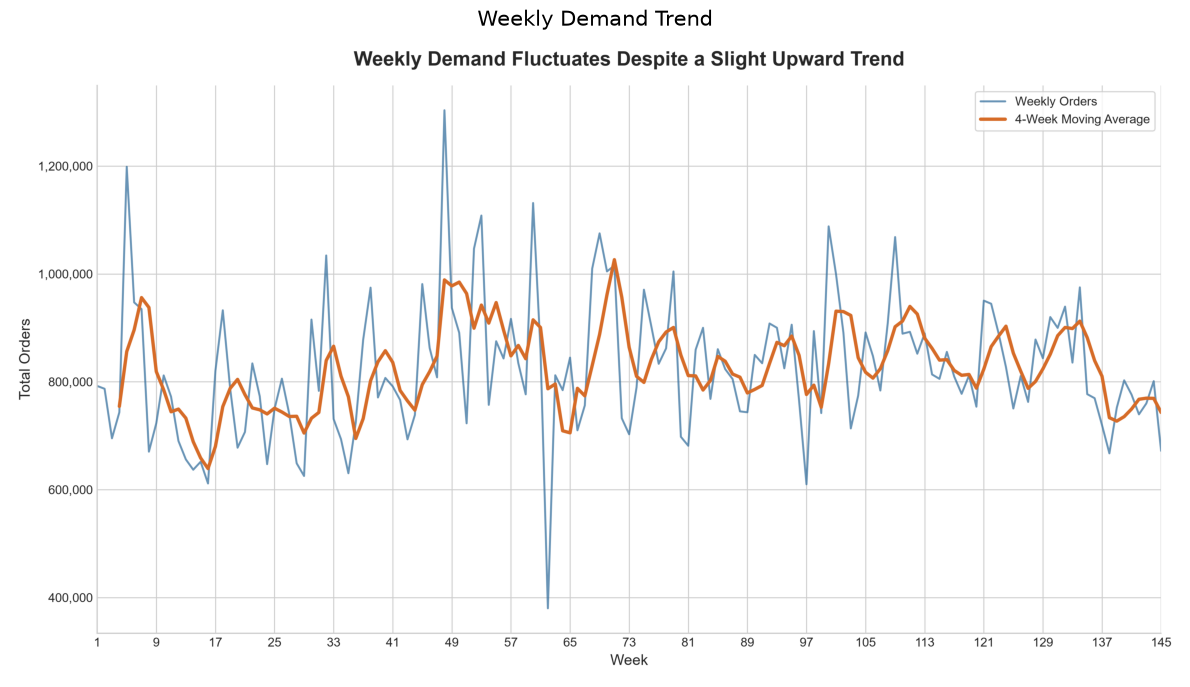

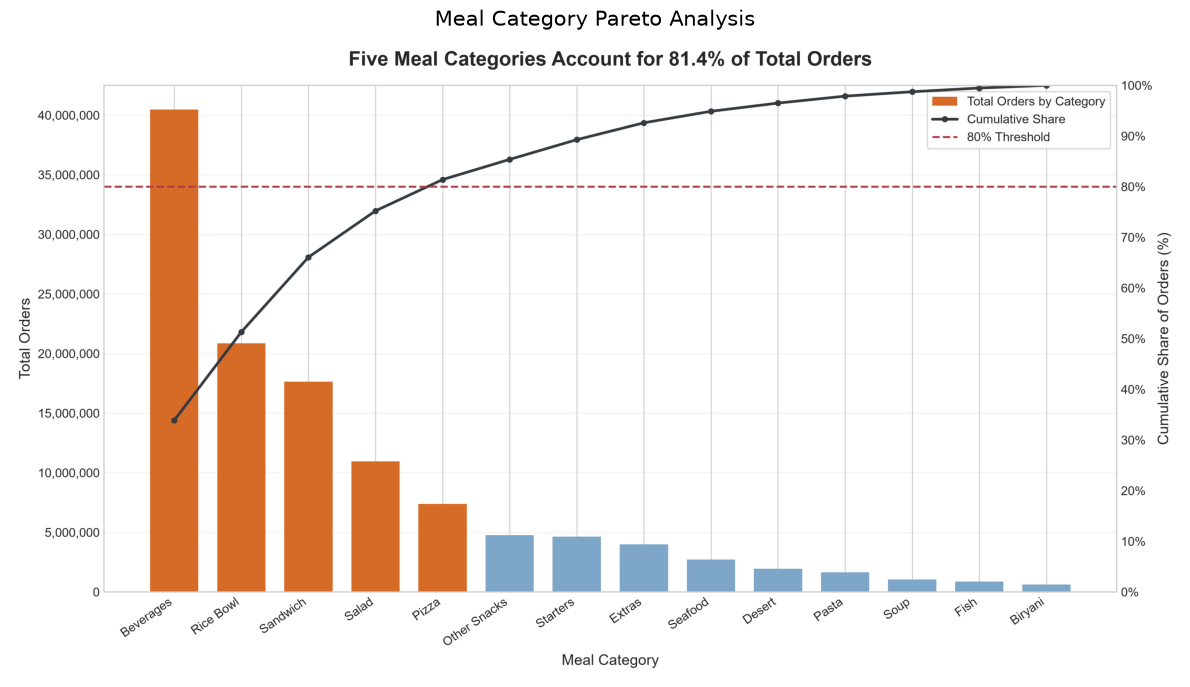

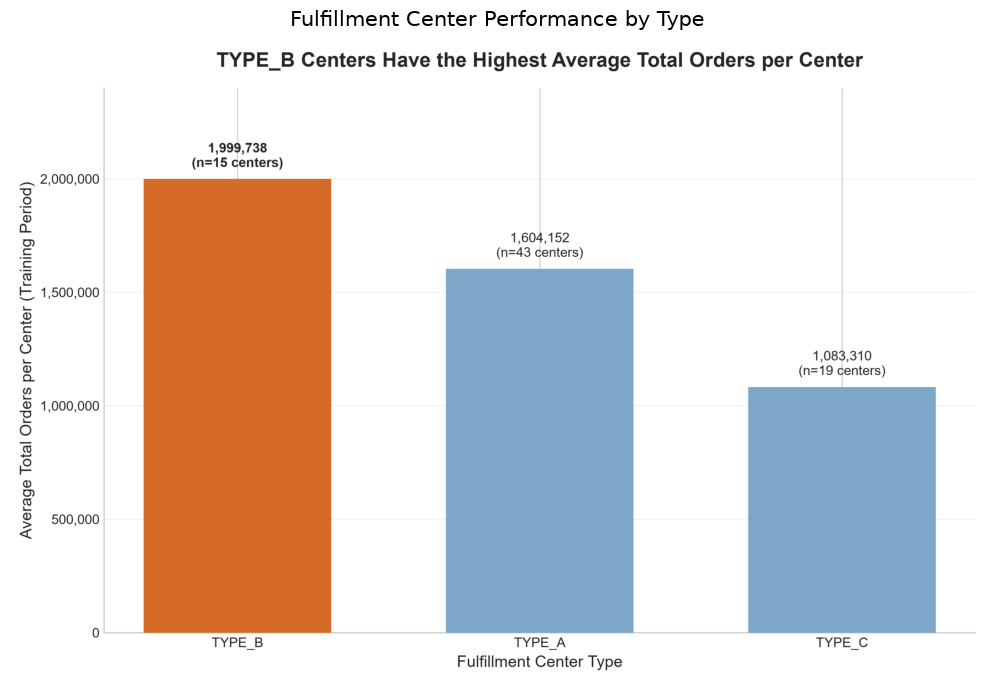

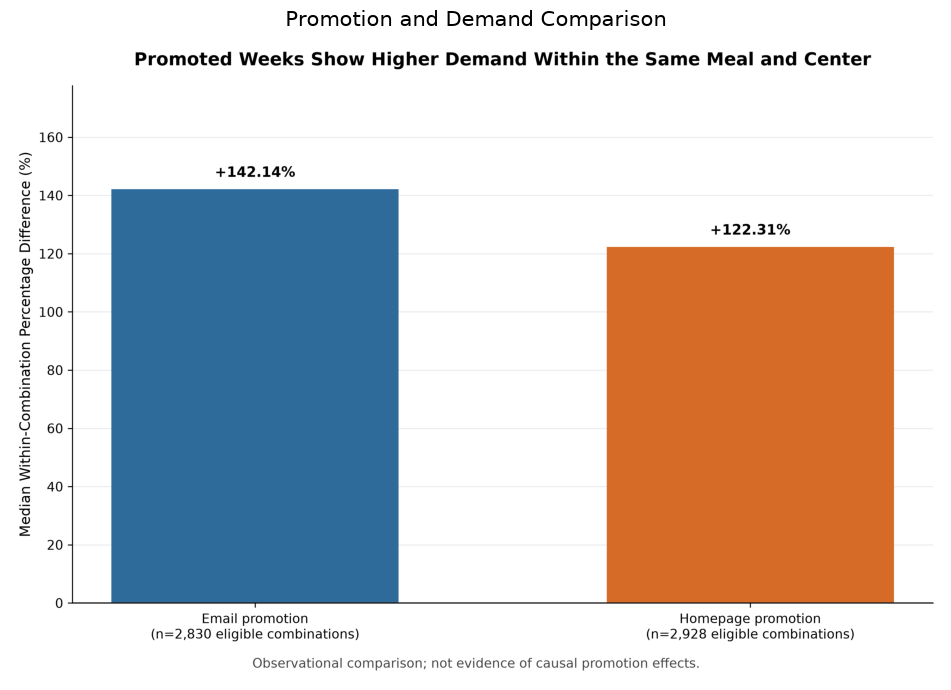

In [10]:
# Display the existing project figures without recreating or modifying them.
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

project_root = next(
    (path.resolve() for path in (Path.cwd(), Path.cwd().parent) if (path / "reports" / "figures").is_dir()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Could not locate the project reports/figures directory from the current folder.")

figure_dir = project_root / "reports" / "figures"
figures = [
    ("weekly_demand_trend.png", "Weekly Demand Trend"),
    ("category_pareto.png", "Meal Category Pareto Analysis"),
    ("center_type_performance.png", "Fulfillment Center Performance by Type"),
    ("promotion_demand_comparison.png", "Promotion and Demand Comparison"),
]

for filename, title in figures:
    image_path = figure_dir / filename
    if not image_path.is_file():
        raise FileNotFoundError(f"Required figure file is missing: {filename}")
    image = mpimg.imread(image_path)
    figure, axis = plt.subplots(figsize=(12, 7))
    axis.imshow(image)
    axis.set_title(title, fontsize=15, pad=12)
    axis.axis("off")
    figure.tight_layout()
    plt.show()
    plt.close(figure)

# Key Findings and Limitations

Summarize the results supported by the preceding analyses, document data-cleaning decisions and assumptions, and distinguish observed associations from causal effects. Note scope limitations, including indexed rather than calendar weeks and the handling of unobserved weeks.

## Key Findings

- **Weekly demand:** Average demand was 824,534.38 orders per week. The first 20 weeks averaged 777,058.20 orders, compared with 805,151.00 in the last 20 weeks (+3.62%). Spearman's rho was 0.1697, indicating a weak positive association between week number and weekly orders rather than a strong, steady trend.
- **Pareto analysis:** The five highest-order categories contributed 81.40% of total orders. The 22 highest-order meals contributed 81.18%; concentration is substantial, but it does not follow a simple 20%-of-meals pattern.
- **Fulfillment centers:** TYPE_A generated the largest aggregate volume (68,978,517 orders across 43 centers), while TYPE_B had the highest average total orders per center (1,999,738.20 across 15 centers). TYPE_C contributed 20,582,895 orders across 19 centers. Aggregate volume and per-center average describe different aspects of performance.
- **Promotions:** Within meal-center pairs observed both with and without promotion, the median percentage difference in mean orders was +142.14% for email promotion and +122.31% for homepage featuring. These are observational comparisons, not causal estimates; repeated weekly observations and other differences may affect the patterns.
- **Discounts:** Discount percentage had a weak positive Spearman association with orders overall (rho = 0.1218). The direction and strength varied by category, so the overall association should not be treated as a causal effect.
- **Demand volatility:** Using observed weeks only, meal 1803 had the lowest CV (14.60%) and was the most stable by this measure; meal 2444 had the highest CV (120.50%) and was the most volatile. CV describes relative variability and should be considered alongside demand volume.

## Limitations

- Week numbers are sequence indices and do not identify specific calendar dates.
- City and region fields are numeric codes, not geographic names.
- Correlations and promotion comparisons describe associations and do not establish causation.
- Weeks absent for a meal or fulfillment center were excluded from its CV calculation, not interpreted as zero orders.
- The currency for the provided prices is unspecified, so revenue derived from price and orders is an estimate in unspecified currency units.

# Bonus — Demand Forecasting

## Stage 1: Temporal validation with a Naive Baseline

This baseline uses only `train.csv`. It is trained on weeks 1-135 and evaluated on weeks 136-145. For each `(center_id, meal_id)` pair, the prediction is the most recent `num_orders` observed through week 135 and is held constant for every validation week. If a pair has no history through week 135, use the mean `num_orders` from the training period as a documented fallback. Validation actuals are used only to calculate MAE and display results; they never contribute to predictions.

In [11]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

bonus_project_root = next(
    (
        path.resolve()
        for path in (Path.cwd(), Path.cwd().parent)
        if (path / "data" / "raw" / "train.csv").is_file()
    ),
    None,
)
if bonus_project_root is None:
    raise FileNotFoundError("Could not locate data/raw/train.csv from the current folder.")

bonus_train_df = pd.read_csv(bonus_project_root / "data" / "raw" / "train.csv")
bonus_required_columns = {"week", "center_id", "meal_id", "num_orders"}
bonus_missing_columns = bonus_required_columns.difference(bonus_train_df.columns)
if bonus_missing_columns:
    raise ValueError(f"train.csv is missing required columns: {sorted(bonus_missing_columns)}")

bonus_train_df["week"] = pd.to_numeric(bonus_train_df["week"], errors="raise")
bonus_train_df["num_orders"] = pd.to_numeric(bonus_train_df["num_orders"], errors="raise")
if not np.isfinite(bonus_train_df[["week", "num_orders"]].to_numpy(dtype=float)).all():
    raise ValueError("Training weeks and num_orders must be finite.")
if (bonus_train_df["num_orders"] < 0).any():
    raise ValueError("Training num_orders must be nonnegative.")
if bonus_train_df.duplicated(["week", "center_id", "meal_id"]).any():
    raise ValueError("train.csv contains duplicate week/center_id/meal_id rows.")

bonus_training_df = bonus_train_df.loc[bonus_train_df["week"].between(1, 135)].copy()
bonus_validation_df = bonus_train_df.loc[bonus_train_df["week"].between(136, 145)].copy()
if bonus_training_df.empty or bonus_validation_df.empty:
    raise ValueError("Both the training and validation periods must contain rows.")
if set(bonus_training_df["week"].unique()) != set(range(1, 136)):
    raise ValueError("Training data must cover every week from 1 through 135.")
if set(bonus_validation_df["week"].unique()) != set(range(136, 146)):
    raise ValueError("Validation data must cover every week from 136 through 145.")

bonus_pair_keys = ["center_id", "meal_id"]
bonus_last_known_df = (
    bonus_training_df.sort_values("week")
    .groupby(bonus_pair_keys, as_index=False, sort=False)
    .tail(1)[bonus_pair_keys + ["num_orders"]]
    .rename(columns={"num_orders": "naive_prediction"})
)
bonus_fallback_value = float(bonus_training_df["num_orders"].mean())

# Build predictions from validation identifiers only; validation num_orders is not available here.
bonus_prediction_df = bonus_validation_df[bonus_pair_keys].merge(
    bonus_last_known_df,
    on=bonus_pair_keys,
    how="left",
    validate="many_to_one",
    indicator=True,
)
bonus_fallback_pairs = bonus_prediction_df.loc[
    bonus_prediction_df["_merge"].eq("left_only"), bonus_pair_keys
].drop_duplicates()
bonus_fallback_count = len(bonus_fallback_pairs)
bonus_prediction_df["naive_prediction"] = bonus_prediction_df[
    "naive_prediction"
].fillna(bonus_fallback_value)
bonus_predictions = bonus_prediction_df["naive_prediction"].to_numpy(dtype=float)

if len(bonus_predictions) != len(bonus_validation_df):
    raise ValueError("Baseline prediction count does not match the validation row count.")
if not np.isfinite(bonus_predictions).all():
    raise ValueError("Baseline predictions contain missing or non-finite values.")
if (bonus_predictions < 0).any():
    raise ValueError("Baseline predictions contain negative values.")
if not bonus_prediction_df.groupby(bonus_pair_keys)["naive_prediction"].nunique().le(1).all():
    raise ValueError("Naive predictions must remain constant per center/meal pair.")

bonus_scored_df = bonus_validation_df[
    ["week", "center_id", "meal_id", "num_orders"]
].reset_index(drop=True).copy()
bonus_scored_df["naive_prediction"] = bonus_predictions
bonus_mae = float(
    np.mean(
        np.abs(
            bonus_scored_df["num_orders"].to_numpy(dtype=float) - bonus_predictions
        )
    )
)
if not np.isfinite(bonus_mae):
    raise ValueError("Baseline MAE is not finite.")

print(f"Training rows (weeks 1-135): {len(bonus_training_df):,}")
print(f"Validation rows (weeks 136-145): {len(bonus_validation_df):,}")
print(f"Distinct validation pairs requiring fallback: {bonus_fallback_count:,}")
print(f"Fallback value (training-period mean): {bonus_fallback_value:,.4f}")
print("Predictions use only information through week 135 and stay constant per pair during validation.")
print(f"Naive Baseline MAE: {bonus_mae:,.4f}")
print("Prediction checks: 0 missing, 0 negative, 0 non-finite values.")
display(bonus_scored_df.head(10))

Training rows (weeks 1-135): 423,727
Validation rows (weeks 136-145): 32,821
Distinct validation pairs requiring fallback: 1
Fallback value (training-period mean): 264.5505
Predictions use only information through week 135 and stay constant per pair during validation.
Naive Baseline MAE: 110.3495
Prediction checks: 0 missing, 0 negative, 0 non-finite values.


,week,center_id,meal_id,num_orders,naive_prediction
0,136,55,1885,134,216.0
1,136,55,1993,216,134.0
2,136,55,2539,163,96.0
3,136,55,2631,95,134.0
4,136,55,1248,14,26.0
5,136,55,1778,136,271.0
6,136,55,1062,310,351.0
7,136,55,2707,95,54.0
8,136,55,1207,230,108.0
9,136,55,1230,134,96.0


## Stage 2: Random Forest temporal validation

Train a `RandomForestRegressor` on weeks 1-135 and evaluate on weeks 136-145. The model uses week, price and promotion fields, categorical center/meal identifiers, and descriptive fields joined from `meal_info.csv` and `fulfilment_center_info.csv`. Reference joins are validated as many-to-one and checked to preserve row counts and total orders. One-hot encoding is fitted only within a scikit-learn pipeline trained on weeks 1-135; validation actual `num_orders` is kept separate from the feature matrix and used only for MAE scoring. No `test.csv` rows are read.

The forest uses 60 trees, maximum depth 18, minimum leaf size 5, `max_features=0.7`, two worker processes, and `random_state=42`. These settings bound model complexity and parallel memory use, although this dataset can still require several minutes to fit.

**Methodological cautions:** this is a single chronological holdout, not cross-validation. Validation weeks 136-145 extend beyond the training-week range; tree models do not extrapolate a time trend beyond observed feature ranges. No lagged order features are used, avoiding target leakage from the validation period. Promotion and price inputs are treated as known-at-prediction features; any operational uncertainty in their availability is not modeled.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

bonus_meal_features_df = pd.read_csv(bonus_project_root / "data" / "raw" / "meal_info.csv")
bonus_center_features_df = pd.read_csv(
    bonus_project_root / "data" / "raw" / "fulfilment_center_info.csv"
)

bonus_join_rows = len(bonus_train_df)
bonus_join_orders = int(bonus_train_df["num_orders"].sum())
bonus_model_df = bonus_train_df.merge(
    bonus_meal_features_df,
    on="meal_id",
    how="left",
    validate="many_to_one",
)
if len(bonus_model_df) != bonus_join_rows or int(bonus_model_df["num_orders"].sum()) != bonus_join_orders:
    raise ValueError("Meal feature join changed training row count or total orders.")
if bonus_model_df[["category", "cuisine"]].isna().any().any():
    raise ValueError("Meal reference join produced missing category or cuisine values.")

bonus_model_df = bonus_model_df.merge(
    bonus_center_features_df,
    on="center_id",
    how="left",
    validate="many_to_one",
)
if len(bonus_model_df) != bonus_join_rows or int(bonus_model_df["num_orders"].sum()) != bonus_join_orders:
    raise ValueError("Center feature join changed training row count or total orders.")
if bonus_model_df[["city_code", "region_code", "center_type", "op_area"]].isna().any().any():
    raise ValueError("Center reference join produced missing center features.")

bonus_rf_training_df = bonus_model_df.loc[bonus_model_df["week"].between(1, 135)].copy()
bonus_rf_validation_df = bonus_model_df.loc[bonus_model_df["week"].between(136, 145)].copy()
bonus_categorical_features = [
    "center_id",
    "meal_id",
    "city_code",
    "region_code",
    "center_type",
    "category",
    "cuisine",
]
bonus_numeric_features = [
    "week",
    "checkout_price",
    "base_price",
    "emailer_for_promotion",
    "homepage_featured",
    "op_area",
]
bonus_model_features = bonus_categorical_features + bonus_numeric_features
if "num_orders" in bonus_model_features:
    raise ValueError("Target leakage: num_orders must not be a model feature.")
if len(bonus_rf_training_df) != len(bonus_training_df):
    raise ValueError("Reference joins unexpectedly changed the training-period row count.")
if len(bonus_rf_validation_df) != len(bonus_validation_df):
    raise ValueError("Reference joins unexpectedly changed the validation-period row count.")

bonus_X_train = bonus_rf_training_df[bonus_model_features]
bonus_y_train = bonus_rf_training_df["num_orders"].to_numpy(dtype=float)
bonus_X_validation = bonus_rf_validation_df[bonus_model_features]
bonus_y_validation = bonus_rf_validation_df["num_orders"].to_numpy(dtype=float)

bonus_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            bonus_categorical_features,
        ),
        ("numeric", "passthrough", bonus_numeric_features),
    ],
    remainder="drop",
)
bonus_rf_model = Pipeline(
    steps=[
        ("preprocess", bonus_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=60,
                max_depth=18,
                min_samples_leaf=5,
                max_features=0.7,
                n_jobs=2,
                random_state=42,
            ),
        ),
    ]
)
bonus_rf_model.fit(bonus_X_train, bonus_y_train)
bonus_rf_raw_predictions = bonus_rf_model.predict(bonus_X_validation)
if not np.isfinite(bonus_rf_raw_predictions).all():
    raise ValueError("Random Forest predictions contain missing or non-finite values.")
bonus_rf_negative_count = int((bonus_rf_raw_predictions < 0).sum())
bonus_rf_predictions = np.maximum(bonus_rf_raw_predictions, 0)
bonus_rf_mae = float(np.mean(np.abs(bonus_y_validation - bonus_rf_predictions)))
if not np.isfinite(bonus_rf_predictions).all() or (bonus_rf_predictions < 0).any():
    raise ValueError("Final Random Forest predictions must be finite and nonnegative.")
if not np.isfinite(bonus_rf_mae):
    raise ValueError("Random Forest MAE is not finite.")

bonus_mae_difference = bonus_rf_mae - bonus_mae
bonus_relative_improvement = (bonus_mae - bonus_rf_mae) / bonus_mae * 100
bonus_comparison_df = pd.DataFrame(
    {
        "Measure": [
            "Naive Baseline MAE",
            "Random Forest MAE",
            "Difference (Random Forest - Naive)",
            "Relative improvement vs. Naive",
        ],
        "Value": [
            bonus_mae,
            bonus_rf_mae,
            bonus_mae_difference,
            bonus_relative_improvement,
        ],
        "Unit": ["orders", "orders", "orders", "%"],
    }
)

bonus_rf_results_df = bonus_rf_validation_df[
    ["week", "center_id", "meal_id", "num_orders"]
].reset_index(drop=True).copy()
bonus_rf_results_df["naive_prediction"] = bonus_predictions
bonus_rf_results_df["random_forest_prediction"] = bonus_rf_predictions

print(f"Training rows (weeks 1-135): {len(bonus_rf_training_df):,}")
print(f"Validation rows (weeks 136-145): {len(bonus_rf_validation_df):,}")
print(
    "Joined row/order totals preserved: "
    f"{bonus_join_rows:,} rows; {bonus_join_orders:,} orders."
)
print(
    "Feature encoding: "
    f"{len(bonus_model_features)} input features, "
    f"{bonus_rf_model.named_steps['preprocess'].transform(bonus_X_train.iloc[:1]).shape[1]} encoded features."
)
print(f"Negative raw Random Forest predictions: {bonus_rf_negative_count}; clipped at zero only if present.")
display(bonus_comparison_df.round(4))
print("First 10 validation rows:")
display(bonus_rf_results_df.head(10).round(3))

Training rows (weeks 1-135): 423,727
Validation rows (weeks 136-145): 32,821
Joined row/order totals preserved: 456,548 rows; 119,557,485 orders.
Feature encoding: 13 input features, 214 encoded features.
Negative raw Random Forest predictions: 0; clipped at zero only if present.


,Measure,Value,Unit
0,Naive Baseline MAE,110.3495,orders
1,Random Forest MAE,69.4827,orders
2,Difference (Random Forest - Naive),-40.8668,orders
3,Relative improvement vs. Naive,37.0339,%


First 10 validation rows:


,week,center_id,meal_id,num_orders,naive_prediction,random_forest_prediction
0,136,55,1885,134,216.0,144.364
1,136,55,1993,216,134.0,176.220
2,136,55,2539,163,96.0,183.437
3,136,55,2631,95,134.0,75.246
4,136,55,1248,14,26.0,63.282
5,136,55,1778,136,271.0,261.398
6,136,55,1062,310,351.0,259.477
7,136,55,2707,95,54.0,247.963
8,136,55,1207,230,108.0,215.963
9,136,55,1230,134,96.0,115.757


## Stage 3: Final training and test predictions

Retrain the Stage 2 Random Forest once on all labeled rows from `train.csv` (weeks 1-145), using the same reference joins, features, preprocessing, and estimator settings. Generate predictions for the original `test.csv` rows for weeks 146-155. No target values are available in `test.csv`; `num_orders` is never included in the test feature matrix. Predictions are clipped to zero only if the model returns negative values, then rounded to the nearest integer. The two-column result is saved as `reports/predictions.csv` in the original test-row order.

In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

bonus_project_root = next(
    (
        path.resolve()
        for path in (Path.cwd(), Path.cwd().parent)
        if (path / "data" / "raw" / "train.csv").is_file()
    ),
    None,
)
if bonus_project_root is None:
    raise FileNotFoundError("Could not locate data/raw/train.csv from the current folder.")

bonus_final_train_df = pd.read_csv(bonus_project_root / "data" / "raw" / "train.csv")
bonus_final_test_df = pd.read_csv(bonus_project_root / "data" / "raw" / "test.csv")
bonus_final_meal_df = pd.read_csv(bonus_project_root / "data" / "raw" / "meal_info.csv")
bonus_final_center_df = pd.read_csv(
    bonus_project_root / "data" / "raw" / "fulfilment_center_info.csv"
)

bonus_final_required_train_columns = {
    "id", "week", "center_id", "meal_id", "checkout_price", "base_price",
    "emailer_for_promotion", "homepage_featured", "num_orders",
}
bonus_final_required_test_columns = bonus_final_required_train_columns - {"num_orders"}
if not bonus_final_required_train_columns.issubset(bonus_final_train_df.columns):
    raise ValueError("train.csv is missing one or more required model columns.")
if not bonus_final_required_test_columns.issubset(bonus_final_test_df.columns):
    raise ValueError("test.csv is missing one or more required prediction columns.")
if "num_orders" in bonus_final_test_df.columns:
    raise ValueError("test.csv unexpectedly contains num_orders; refusing to use test targets.")
if bonus_final_train_df["id"].duplicated().any():
    raise ValueError("train.csv contains duplicate ids.")
if bonus_final_test_df["id"].duplicated().any():
    raise ValueError("test.csv contains duplicate ids.")

bonus_final_train_df["week"] = pd.to_numeric(bonus_final_train_df["week"], errors="raise")
bonus_final_train_df["num_orders"] = pd.to_numeric(
    bonus_final_train_df["num_orders"], errors="raise"
)
bonus_final_test_df["week"] = pd.to_numeric(bonus_final_test_df["week"], errors="raise")
if set(bonus_final_train_df["week"].unique()) != set(range(1, 146)):
    raise ValueError("Final training data must cover weeks 1 through 145.")
if set(bonus_final_test_df["week"].unique()) != set(range(146, 156)):
    raise ValueError("test.csv must cover weeks 146 through 155.")
if len(bonus_final_test_df) != 32573:
    raise ValueError(f"Expected 32,573 test rows, found {len(bonus_final_test_df):,}.")

bonus_final_train_rows_before = len(bonus_final_train_df)
bonus_final_orders_before = int(bonus_final_train_df["num_orders"].sum())
bonus_final_train_df = bonus_final_train_df.merge(
    bonus_final_meal_df,
    on="meal_id",
    how="left",
    validate="many_to_one",
)
if (
    len(bonus_final_train_df) != bonus_final_train_rows_before
    or int(bonus_final_train_df["num_orders"].sum()) != bonus_final_orders_before
):
    raise ValueError("Meal join changed training row count or total orders.")
if bonus_final_train_df[["category", "cuisine"]].isna().any().any():
    raise ValueError("Meal join produced missing reference features.")

bonus_final_train_df = bonus_final_train_df.merge(
    bonus_final_center_df,
    on="center_id",
    how="left",
    validate="many_to_one",
)
if (
    len(bonus_final_train_df) != bonus_final_train_rows_before
    or int(bonus_final_train_df["num_orders"].sum()) != bonus_final_orders_before
):
    raise ValueError("Center join changed training row count or total orders.")
if bonus_final_train_df[["city_code", "region_code", "center_type", "op_area"]].isna().any().any():
    raise ValueError("Center join produced missing reference features.")

bonus_final_original_ids = bonus_final_test_df["id"].reset_index(drop=True).copy()
bonus_final_test_df["_original_row_order"] = np.arange(len(bonus_final_test_df))
bonus_final_test_df = bonus_final_test_df.merge(
    bonus_final_meal_df,
    on="meal_id",
    how="left",
    validate="many_to_one",
    sort=False,
)
if len(bonus_final_test_df) != len(bonus_final_original_ids):
    raise ValueError("Meal join changed test row count.")
bonus_final_test_df = bonus_final_test_df.merge(
    bonus_final_center_df,
    on="center_id",
    how="left",
    validate="many_to_one",
    sort=False,
)
if len(bonus_final_test_df) != len(bonus_final_original_ids):
    raise ValueError("Center join changed test row count.")
bonus_final_test_df = bonus_final_test_df.sort_values("_original_row_order").reset_index(drop=True)
if not bonus_final_test_df["id"].reset_index(drop=True).equals(bonus_final_original_ids):
    raise ValueError("Reference joins changed original test id order.")
if bonus_final_test_df[["category", "cuisine", "city_code", "region_code", "center_type", "op_area"]].isna().any().any():
    raise ValueError("Test reference joins produced missing model features.")

bonus_final_categorical_features = [
    "center_id", "meal_id", "city_code", "region_code", "center_type", "category", "cuisine"
]
bonus_final_numeric_features = [
    "week", "checkout_price", "base_price", "emailer_for_promotion", "homepage_featured", "op_area"
]
bonus_final_features = bonus_final_categorical_features + bonus_final_numeric_features
if "num_orders" in bonus_final_features:
    raise ValueError("Target leakage: num_orders must not be a prediction feature.")

bonus_final_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            bonus_final_categorical_features,
        ),
        ("numeric", "passthrough", bonus_final_numeric_features),
    ],
    remainder="drop",
)
bonus_final_model = Pipeline(
    steps=[
        ("preprocess", bonus_final_preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=60,
                max_depth=18,
                min_samples_leaf=5,
                max_features=0.7,
                n_jobs=2,
                random_state=42,
            ),
        ),
    ]
)
bonus_final_model.fit(
    bonus_final_train_df[bonus_final_features],
    bonus_final_train_df["num_orders"].to_numpy(dtype=float),
)
bonus_final_raw_predictions = bonus_final_model.predict(
    bonus_final_test_df[bonus_final_features]
)
if not np.isfinite(bonus_final_raw_predictions).all():
    raise ValueError("Raw predictions contain missing or non-finite values.")
bonus_final_negative_count = int((bonus_final_raw_predictions < 0).sum())
bonus_final_predictions = np.rint(np.maximum(bonus_final_raw_predictions, 0)).astype("int64")

bonus_final_output_df = pd.DataFrame(
    {
        "id": bonus_final_test_df["id"].to_numpy(copy=True),
        "num_orders": bonus_final_predictions,
    }
)
if list(bonus_final_output_df.columns) != ["id", "num_orders"]:
    raise ValueError("Prediction output must contain exactly id,num_orders columns.")
if len(bonus_final_output_df) != 32573:
    raise ValueError("Prediction count does not match the required 32,573 rows.")
if bonus_final_output_df["id"].duplicated().any():
    raise ValueError("Prediction output contains duplicate ids.")
if not bonus_final_output_df["id"].reset_index(drop=True).equals(bonus_final_original_ids):
    raise ValueError("Prediction id sequence does not match original test.csv order.")
if bonus_final_output_df["num_orders"].isna().any():
    raise ValueError("Prediction output contains missing num_orders.")
if not np.issubdtype(bonus_final_output_df["num_orders"].dtype, np.number):
    raise TypeError("num_orders predictions must be numeric.")
if not np.isfinite(bonus_final_output_df["num_orders"].to_numpy(dtype=float)).all():
    raise ValueError("Prediction output contains non-finite num_orders.")
if (bonus_final_output_df["num_orders"] < 0).any():
    raise ValueError("Prediction output contains negative num_orders.")

bonus_prediction_path = bonus_project_root / "reports" / "predictions.csv"
bonus_final_output_df.to_csv(bonus_prediction_path, index=False)

bonus_saved_predictions_df = pd.read_csv(bonus_prediction_path)
if list(bonus_saved_predictions_df.columns) != ["id", "num_orders"]:
    raise ValueError("Saved CSV does not have exactly the required columns.")
if len(bonus_saved_predictions_df) != 32573:
    raise ValueError("Saved CSV does not contain exactly 32,573 predictions.")
if not bonus_saved_predictions_df["id"].equals(bonus_final_original_ids):
    raise ValueError("Saved CSV ids or their order differ from test.csv.")
if bonus_saved_predictions_df["id"].duplicated().any():
    raise ValueError("Saved CSV contains duplicate ids.")
if bonus_saved_predictions_df["num_orders"].isna().any():
    raise ValueError("Saved CSV contains missing num_orders.")
if not np.isfinite(bonus_saved_predictions_df["num_orders"].to_numpy(dtype=float)).all():
    raise ValueError("Saved CSV contains non-finite num_orders.")
if (bonus_saved_predictions_df["num_orders"] < 0).any():
    raise ValueError("Saved CSV contains negative num_orders.")

print(f"Final training rows (weeks 1-145): {len(bonus_final_train_df):,}")
print(f"Test rows (weeks 146-155): {len(bonus_final_test_df):,}")
print(
    "Training joins preserved: "
    f"{bonus_final_train_rows_before:,} rows and {bonus_final_orders_before:,} orders."
)
print("Test joins preserved row count and original id order.")
print(f"Negative raw predictions clipped at zero: {bonus_final_negative_count:,}")
print(f"Saved and verified: {bonus_prediction_path.relative_to(bonus_project_root)}")
print("Validation: 32,573 rows; columns id,num_orders; ids unique and in original order; no missing, non-finite, or negative values.")
print("First 10 predictions:")
print(bonus_saved_predictions_df.head(10).to_string(index=False))
print("Prediction summary statistics:")
print(bonus_saved_predictions_df["num_orders"].describe().to_string())

Final training rows (weeks 1-145): 456,548
Test rows (weeks 146-155): 32,573
Training joins preserved: 456,548 rows and 119,557,485 orders.
Test joins preserved row count and original id order.
Negative raw predictions clipped at zero: 0
Saved and verified: reports\predictions.csv
Validation: 32,573 rows; columns id,num_orders; ids unique and in original order; no missing, non-finite, or negative values.
First 10 predictions:
     id  num_orders
1028232         122
1127204         157
1212707         171
1082698          51
1400926          45
1284113         239
1197966         266
1132739         217
1057981         116
1095932         138
Prediction summary statistics:
count    32573.000000
mean       263.277684
std        403.339181
min         16.000000
25%         70.000000
50%        143.000000
75%        291.000000
max       6990.000000
